# Введение в Jupyter и молекулярную динамику

**Лабораторная работа:** знакомство с вычислительным практикумом

**Цель:** научиться запускать Jupyter Notebook и понять, как из физических законов строится расчёт молекулярной динамики.

**Исследуемая система:** две взаимодействующие частицы калия в плоскости; далее в комплекте рассматривается ансамбль из 1035 частиц.

**Ожидаемый результат:** график потенциала Леннарда — Джонса и понимание того, какие данные потребуются для пяти расчётных работ.

**Студент:** ____________________  **Группа:** __________  **Преподаватель:** ____________________

> Сначала запустите каждую ячейку этой работы сверху вниз. Для расчётных ноутбуков выберите `DEMO` или `FULL` в первой конфигурационной ячейке. Каждый notebook содержит весь код и запускается в Colab самостоятельно.

## 1. Как работать с ноутбуком

Jupyter Notebook — это интерактивный документ, в котором рядом находятся объяснения, формулы, Python-код и результат его выполнения. Ячейки выполняются по одной или все подряд. В JupyterLab нажмите **Shift+Enter**, чтобы выполнить выбранную ячейку и перейти к следующей; в VS Code используйте кнопку ▶ над ячейкой. Команда **Run All / Выполнить все** запускает документ сверху вниз.

- **Markdown-ячейка** содержит текст, таблицы и формулы. Чтобы увидеть оформленный текст, достаточно выполнить ячейку.
- **Python-ячейка** содержит команды. После выполнения результат появится непосредственно под ней.
- Ячейки используют общую память ядра. Если ячейка ниже обращается к переменной, созданной выше, сначала выполните верхнюю. Поэтому после изменения раннего параметра перезапустите ядро и выберите «Restart Kernel and Run All».
- Сохраните notebook (`Ctrl+S`). Для сдачи оставьте в документе код, объяснения и результаты успешного выполнения.

Сообщение об ошибке обычно заканчивается названием типа ошибки и строкой, где она возникла. Например, `NameError` означает, что Python не знает указанное имя: часто опечатались или пропустили ячейку с присваиванием. `ImportError` часто указывает на неверно выбранное виртуальное окружение. Не удаляйте строку ошибки: по ней можно понять, какую операцию проверить.

## 2. Самые нужные понятия Python

**Переменная** — имя, связанное со значением. Знак `=` присваивает значение справа имени слева; это не равенство из уравнения. Числа записываются без кавычек, строки — в кавычках, список — в квадратных скобках, словарь — в фигурных скобках с парами «ключ: значение».

**Функция** — именованный набор действий. Запись `np.mean(values)` вызывает функцию `mean` из библиотеки NumPy и передаёт ей аргумент `values`. Запись `np.sqrt(x)` вычисляет квадратный корень. Аргумент можно передать по имени, например `np.std(values, ddof=1)`: `ddof=1` просит вычислить выборочное стандартное отклонение. Функция может вернуть одно или несколько значений.

**Библиотека** — готовый набор функций и типов. `import numpy as np` подключает NumPy и даёт ему короткое имя `np`; `from pathlib import Path` импортирует конкретный класс `Path`. Импорт не запускает весь расчёт — он делает выбранные инструменты доступными.

**Массив NumPy** хранит много однотипных чисел и позволяет выполнять над ними операции сразу. Например, `velocities[:, 0]` означает все строки и столбец с индексом 0 (компонента скорости по x). Индексация в Python начинается с нуля. Цикл `for` повторяет блок для каждого элемента; условие `if` выполняет блок только при истинном условии.

Ниже показаны переменная, список, словарь, массив, функция, цикл и условие. Эта ячейка не моделирует систему — она только знакомит с синтаксисом.

### Вычислительное ядро внутри notebook

Ниже приведён весь код, необходимый для расчёта. Блоки расположены в порядке зависимостей: от физических параметров к силам и интегратору. Каждый блок можно читать, изменять и выполнять как обычную Python-ячейку; скрытой загрузки кода нет.

In [ ]:
from pathlib import Path

# В Colab это /content; локально — каталог, из которого открыт notebook.
PROJECT_ROOT = Path.cwd()
print(f'Рабочий каталог: {PROJECT_ROOT}; результаты будут сохранены в output/')

#### Физические константы и параметры взаимодействия

Задаём единицы СИ, массу атома калия и параметры потенциалов K–K и K–C. Все энергии относятся к одной взаимодействующей паре, а не к молю.

In [ ]:
"""Physical constants and the fixed material parameters of the model.

The simulation core uses SI units. Energies are per particle, not per mole.
"""

from __future__ import annotations

from dataclasses import dataclass
import math


AVOGADRO = 6.022_140_76e23  # 1/mol, exact
BOLTZMANN = 1.380_649e-23  # J/K, exact
ATOMIC_MASS_UNIT = 1.660_539_066_60e-27  # kg

KELVIN_OFFSET_CELSIUS = 273.15
TEMPERATURE_C = 900.0
TEMPERATURE_K = TEMPERATURE_C + KELVIN_OFFSET_CELSIUS

MASS_K = 39.0983 * ATOMIC_MASS_UNIT
SIGMA_K = 0.4250e-9  # m
EPSILON_K = 850.0 * BOLTZMANN  # J/particle

# UFF C_3 values are used only for the fixed diamond wall. UFF lists the
# minimum position x and well depth D; sigma=x/2**(1/6) maps that minimum to
# the conventional 12-6 LJ form used by this project.
SIGMA_C = (3.851e-10) / (2.0 ** (1.0 / 6.0))
EPSILON_C = 0.105 * 4184.0 / AVOGADRO  # 0.105 kcal/mol -> J/particle
SIGMA_KC = 0.5 * (SIGMA_K + SIGMA_C)
EPSILON_KC = math.sqrt(EPSILON_K * EPSILON_C)
DIAMOND_LATTICE_CONSTANT = 0.3567e-9  # m
WALL_SPACING = DIAMOND_LATTICE_CONSTANT / math.sqrt(2.0)

LAYER_THICKNESS = (1.0e-3 / (4.0 * AVOGADRO)) ** (1.0 / 3.0)


@dataclass(frozen=True)
class LJParameters:
    sigma: float
    epsilon: float

    def __post_init__(self) -> None:
        if self.sigma <= 0.0 or self.epsilon <= 0.0:
            raise ValueError("LJ sigma and epsilon must be positive")

    @property
    def r_min(self) -> float:
        return 2.0 ** (1.0 / 6.0) * self.sigma

    @property
    def timescale(self) -> float:
        return self.sigma * math.sqrt(MASS_K / self.epsilon)


K_LJ = LJParameters(SIGMA_K, EPSILON_K)
C_LJ = LJParameters(SIGMA_C, EPSILON_C)
KC_LJ = LJParameters(SIGMA_KC, EPSILON_KC)


In [1]:
from pathlib import Path  # переносимые пути к файлам
import numpy as np  # Подключаем NumPy для массивов и математических функций

temperatures = [300.0, 600.0, 900.0]  # список из трёх чисел, единица — K
experiment = {"substance": "K", "box_nm": [24.0, 24.0]}  # словарь с подписями-ключами
temperature_array = np.array(temperatures)  # превращаем список в числовой массив
mean_temperature = np.mean(temperature_array)  # возвращаем среднее значение массива

for temperature in temperature_array:  # цикл последовательно берёт каждую температуру
    if temperature >= 600.0:  # проверяем условие для текущего числа
        print(f"{experiment['substance']}: T = {temperature:.0f} K")  # печатаем форматированную строку
print(f"Среднее значение списка: {mean_temperature:.1f} K")
print(f"Корень из среднего: {np.sqrt(mean_temperature):.2f} sqrt(K)")


K: T = 600 K
K: T = 900 K
Среднее значение списка: 600.0 K
Корень из среднего: 24.49 sqrt(K)


## 3. Что моделирует молекулярная динамика

Молекулярная динамика (МД) — способ численно проследить движение частиц. Для каждого атома задаются координаты $\mathbf r_i$, скорость $\mathbf v_i$ и масса $m_i$. Силы получают из потенциальной энергии $U$: $\mathbf F_i=-\nabla_i U$. Затем уравнения Ньютона интегрируются по небольшим временным шагам.

Для нейтральных сферически симметричных частиц часто используют парный потенциал Леннарда — Джонса:

$$U_{LJ}(r)=4\varepsilon\left[\left(\frac{\sigma}{r}\right)^{12}-\left(\frac{\sigma}{r}\right)^6\right].$$

Здесь $r$ — расстояние между центрами частиц (м), $\varepsilon$ — глубина потенциальной ямы (Дж на пару частиц), $\sigma$ — расстояние, на котором $U=0$ (м). При малом $r$ член $r^{-12}$ резко отталкивает атомы; при большем расстоянии член $-r^{-6}$ описывает притяжение дисперсионной природы. Минимум находится при $r_{min}=2^{1/6}\sigma$ и равен $-\varepsilon$.

Для экономии вычислений применяется обрезанный сдвинутый потенциал (LJTS): $U(r)=U_{LJ}(r)-U_{LJ}(r_c)$ при $r<r_c$ и $U(r)=0$ при $r\ge r_c$. Энергия непрерывна у cutoff $r_c$, но сила там может быть разрывной. В этом проекте задан $r_c=2.5\sigma$.

Начальные координаты в расчётах размещаются на слегка возмущённой решётке, чтобы избежать случайного наложения частиц. Каждая компонента начальной скорости выбирается из распределения Максвелла $N(0,k_BT/m)$. Общую скорость центра масс удаляют, затем скорости однократно масштабируют к заданной температуре. `seed` (начальное число генератора случайных чисел) позволяет повторить те же координаты и скорости.

Периодические граничные условия (PBC) означают, что противоположные стороны коробки соседствуют: ушедшая за правый край частица входит слева. Minimum image выбирает кратчайшее периодическое расстояние между парой. Углеродные стенки — другая модель границы: фиксированные атомы отталкивают и притягивают газ, а координаты стенки остаются неизменными.

В алгоритме Velocity Verlet координата обновляется как $\mathbf r(t+\Delta t)=\mathbf r(t)+\mathbf v(t)\Delta t+\frac12\mathbf a(t)\Delta t^2$, после перерасчёта сил скорость обновляется средней старой и новой акселерацией. Шаг $\Delta t$ в проекте равен 1 фс. При слишком крупном шаге интегратор может давать заметный дрейф энергии или нестабильную траекторию.

**Двумерная модель — учебное приближение.** Частицы имеют только координаты x и y, поэтому для $N$ атомов доступны $2N$ поступательных степеней свободы, а не $3N$. Модель не описывает толщину слоя, движение по z, электронную структуру металлического калия и многие многочастичные эффекты. Давление вычисляется на площадь и имеет единицы $\mathrm{J/m^2= N/m}$; паскали получаются только после условного деления на принятую толщину слоя.

### Параметры иллюстрационного примера

| Параметр | Значение | Единица | Смысл |
|---|---:|---|---|
| $\sigma_{KK}$ | 0.4250 | нм | Нулевое пересечение несдвинутого LJ |
| $\varepsilon_{KK}/k_B$ | 850 | K | $\varepsilon=850k_B$ Дж на пару |
| $r_{min}$ | $2^{1/6}\sigma$ | нм | Расстояние минимума потенциала |
| $r_c$ | $2.5\sigma$ | нм | Радиус обрезания LJTS |

Значения K–K взяты из параметров учебного ядра; точная первичная публикация для этой пары чисел в репозитории не указана. Это иллюстрационные параметры модели, не гарантия точного описания реального калия.

## 4. Пример: энергия пары частиц и график

В этом блоке импортируются параметры K–K, создаётся массив расстояний в нанометрах и поэлементно вычисляется LJTS. `np.linspace` возвращает 400 равномерных точек между 0.80 и 1.70 нм. В коде коэффициенты переводятся в метры, а энергия — в джоули на пару частиц. `matplotlib.pyplot` создаёт график; `plot` соединяет вычисленные точки линией, `xlabel` и `ylabel` задают русские подписи осей. Массивы не являются картинками: рисунок строится по паре числовых столбцов.

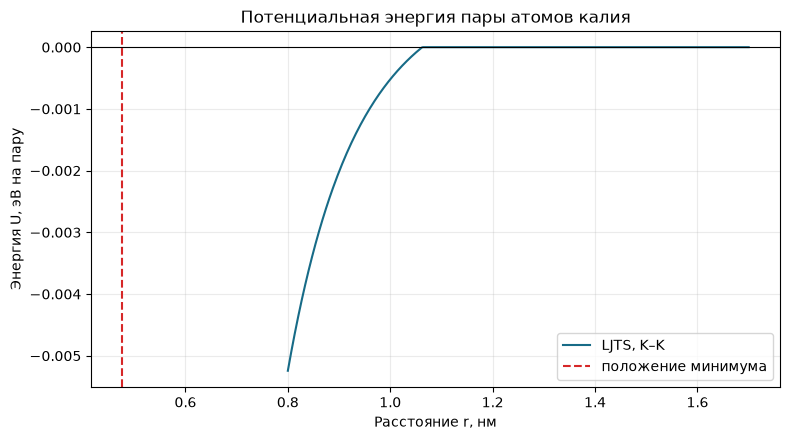

In [2]:
import matplotlib.pyplot as plt  # библиотека построения графиков

distance_nm = np.linspace(0.80, 1.70, 400)  # список расстояний в нанометрах
distance_m = distance_nm * 1e-9  # переводим нм в м: 1 нм = 10^-9 м
sigma = K_LJ.sigma  # обращаемся к атрибуту sigma объекта параметров
epsilon = K_LJ.epsilon  # энергия одной пары в джоулях
cutoff = 2.5 * sigma  # радиус обрезания потенциала в метрах
sr6 = (sigma / distance_m) ** 6  # шестая степень безразмерного отношения sigma/r
sr6_cut = (sigma / cutoff) ** 6  # такое же отношение на границе cutoff
u_lj = 4 * epsilon * (sr6**2 - sr6)  # энергия LJ для каждой точки массива
u_cut = 4 * epsilon * (sr6_cut**2 - sr6_cut)  # энергия в cutoff, вычитаем её для непрерывности
energy_ev = (u_lj - u_cut) / 1.602176634e-19  # Дж переводим в эВ на пару
energy_ev[distance_m >= cutoff] = 0.0  # за cutoff пары не взаимодействуют в LJTS

fig, ax = plt.subplots(figsize=(8, 4.5))  # создаём рисунок и область координат
ax.plot(distance_nm, energy_ev, color="#176b87", label="LJTS, K–K")
ax.axhline(0, color="black", linewidth=0.8)  # линия нулевой энергии
ax.axvline(K_LJ.r_min * 1e9, color="tab:red", linestyle="--", label="положение минимума")
ax.set(title="Потенциальная энергия пары атомов калия", xlabel="Расстояние r, нм", ylabel="Энергия U, эВ на пару")
ax.grid(alpha=0.25)  # лёгкая сетка помогает оценивать значения
ax.legend()  # отображаем пояснение к линиям
fig.tight_layout()  # подбираем поля рисунка
plt.show()  # выводим рисунок под ячейкой


### Интерпретация примера

На коротких расстояниях энергия резко возрастает — это отражает сильное отталкивание при перекрытии электронных оболочек. Яма ниже нуля соответствует притяжению; её минимум равен $-\varepsilon$. На cutoff сдвинутая энергия плавно достигает нуля, после cutoff взаимодействие отключено. Для реальных атомов калия простая парная LJ-модель не является исчерпывающим описанием металлической связи; график демонстрирует математическую модель, принятую в учебном коде.

## 5. Как читать результаты остальных работ

У NVE-расчёта (постоянные число частиц, объём и полная энергия) кинетическая и потенциальная энергии обычно обмениваются, тогда как их сумма должна оставаться близкой к постоянной. Температура мгновенно флуктуирует, давление содержит кинетический и вириальный вклады. В ансамбле NVE температура не фиксируется термостатом. Чтобы назвать давление равновесным, одной красивой полки на графике недостаточно: нужно проверить отсутствие заметного тренда и оценить неопределённость с учётом корреляции временных наблюдений.

Каждая расчётная работа открывается отдельно и повторно задаёт свои импорты и параметры — её можно запускать самостоятельно. Во введении классы далее не требуются, но в ядре класс `MDEngine` объединяет конфигурацию, состояние частиц и операцию одного шага: объект создаётся как `engine = MDEngine(config)`, а метод `engine.step()` меняет состояние на следующий момент времени и возвращает словарь наблюдаемых величин.

## 6. Вопросы для защиты

1. **Чем отличаются Markdown- и Python-ячейки?** Markdown оформляет текст и формулы; Python исполняет вычисления.
2. **Зачем важен порядок ячеек?** Поздняя ячейка использует переменные, которые создали ранние.
3. **Что такое переменная?** Имя, которому присвоено значение для последующего использования.
4. **Что делает `import numpy as np`?** Подключает инструменты NumPy и позволяет обращаться к ним через короткое имя `np`.
5. **Чем список отличается от NumPy-массива?** Список — универсальная последовательность Python; массив ориентирован на численные операции над многими элементами.
6. **Почему нужен seed?** Он фиксирует псевдослучайную последовательность, чтобы повторить и сравнить расчёт.
7. **Что физически означает минимум LJ-потенциала?** Устойчивое расстояние пары, при котором суммарная сила равна нулю, а энергия минимальна.
8. **Зачем нужен маленький временной шаг?** Чтобы численно разрешить движение и изменение сил между соседними моментами времени.
9. **Почему 2D-результат нельзя без оговорок считать свойством объёмного калия?** В модели нет третьего измерения и электронных/многочастичных эффектов металла.
10. **Что делать после ошибки?** Прочитать тип ошибки и ячейку, проверить пропущенные предыдущие ячейки и при необходимости перезапустить ядро с выполнением сверху вниз.